###  Libraries

In [1]:
# Import libraries
import numpy as np
import torch
import sys
from Datasets.Datasets import get_dataset
from Autoencoder import Autoencoder, CD_Autoencoder
from Visualization import Visualization
from General_Functions import General_Functions

### Global Variables

In [2]:
# Set path to module
path_to_module = './'
sys.path.append(path_to_module)

# Set device (cuda or cpu)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.cuda.set_device(device)

# Set random seeds (runs repeat only from a fresh kernel with all cells run in order) - for more info look here : https://docs.pytorch.org/docs/2.15/notes/randomness.html
seed = 42
torch.manual_seed(seed) # torch, CPU and GPU: layer weights, RBF centres, batch order of the dataloader
np.random.seed(seed) # numpy: k-means initialization, t-SNE, plot colours . Careful , when dataset = "synthetic" it overrides the seed to 42 !!!
torch.backends.cudnn.deterministic = True # GPU: cuDNN uses only deterministic convolution algorithms
torch.backends.cudnn.benchmark = False # GPU: cuDNN does not test and pick a (possibly different) fastest algorithm each run

### Visualization

In [3]:
visualization = Visualization()

### Load Dataset

In [4]:
# Set dataset_name, module_name, batch_size and n_clusters
dataset_name = "emnist_balanced_letters_U_Z" # The available datasets are: emnist_balanced_digits, emnist_mnist, emnist_balanced_letters_A_J, emnist_balanced_letters_K_T, emnist_balanced_letters_U_Z, har, pendigits, waveform_v1, synthetic
batch_size = 256
n_clusters = 6

# Get dataloader, input_dim, data_np and labels
dataloader, input_dim, data_np, labels = get_dataset(dataset_name, batch_size)
print('Data_Shape is:', input_dim) # for image datasets , data shape == channel
print('Batches Number is:', len(dataloader))
print(np.unique(labels))

Data_Shape is: 1
Batches Number is: 66
[30 31 32 33 34 35]


### Constraint Matrix

In [5]:
# Make constraint matrix from the labels of the whole dataset
constraint_matrix = General_Functions().make_constraint_matrix(labels, optimizer_version=True)

### Parameters

In [6]:
# Set latent dimension and negative slope
latent_dim = 10
negative_slope = 0

# Set pre-training epochs and learning rate
n_pret_epochs = 100
pret_lr = 1e-3

# Set lamdas, training epochs and learning rate
sil_lambda = 0.01 # 0.01
entr_lambda = 0.01 # 0.01
semi_lambda =  0.0000008
n_epochs = 100
lr = 5e-4

# Set use_pretrain and is_mlp_ae
use_pretrain = True # Set True for pretraining autoencoder or set False for using already pretrained weights
is_mlp_ae = False # Set True for tabular datasets e.g. pendigits or set False for image datasets e.g. emnist_mnist

### Create Autoencoder Model

In [7]:
if is_mlp_ae:
    autoencoder = Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)
else:
    autoencoder = CD_Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)

autoencoder.set_general_training_variables(dataloader=dataloader, batch_size=batch_size)
autoencoder.set_pretraining_variables(n_pret_epochs=n_pret_epochs, pret_lr=pret_lr)
autoencoder.set_training_variables(n_epochs=n_epochs, lr=lr, sil_lambda=sil_lambda, entr_lambda=entr_lambda)
autoencoder.set_path_variables(path_to_module=path_to_module, dataset_name=dataset_name)
autoencoder.set_path()
autoencoder = autoencoder.to(device)

### Pretrain Autoencoder

In [8]:
if(use_pretrain):
    autoencoder.pretrain_autoencoder()
    autoencoder.save_pretrained_weights()
else:
    model_save_path = autoencoder.data_dir_path + '/Weigths/autoencoder_weights.pth'
    autoencoder.load_state_dict(torch.load(model_save_path))

Epoch: 0, Loss: 40.495798
Epoch: 1, Loss: 28.001001
Epoch: 2, Loss: 22.242198
Epoch: 3, Loss: 17.839342
Epoch: 4, Loss: 14.288524
Epoch: 5, Loss: 11.412158
Epoch: 6, Loss: 9.041223
Epoch: 7, Loss: 7.191878
Epoch: 8, Loss: 5.644696
Epoch: 9, Loss: 4.449833
Epoch: 10, Loss: 3.514867
Epoch: 11, Loss: 2.791848
Epoch: 12, Loss: 2.254336
Epoch: 13, Loss: 1.843941
Epoch: 14, Loss: 1.569377
Epoch: 15, Loss: 1.384778
Epoch: 16, Loss: 1.215404
Epoch: 17, Loss: 1.123484
Epoch: 18, Loss: 1.066375
Epoch: 19, Loss: 0.996523
Epoch: 20, Loss: 0.973161
Epoch: 21, Loss: 0.957741
Epoch: 22, Loss: 0.938286
Epoch: 23, Loss: 0.913594
Epoch: 24, Loss: 0.907790
Epoch: 25, Loss: 0.909240
Epoch: 26, Loss: 0.892350
Epoch: 27, Loss: 0.881742
Epoch: 28, Loss: 0.889817
Epoch: 29, Loss: 0.884103
Epoch: 30, Loss: 0.878752
Epoch: 31, Loss: 0.871270
Epoch: 32, Loss: 0.868395
Epoch: 33, Loss: 0.866492
Epoch: 34, Loss: 0.857234
Epoch: 35, Loss: 0.870572
Epoch: 36, Loss: 0.850406
Epoch: 37, Loss: 0.839386
Epoch: 38, Loss:

### Initialize the clustering layer using k-means

In [9]:
autoencoder.kmeans_initialization(n_init=100)

ACC: 0.76 PUR: 0.76 NMI: 0.61 ARI: 0.57


### Train Autoencoder

In [10]:
latent_data, labels, clustering = autoencoder.train_semi_supervised_autoencoder(constraint_matrix=constraint_matrix, semi_lambda=semi_lambda)

Ep: 0 Rec L: 0.6867 Cl L: 0.6676 Entropy: 1.6994 SSil: -0.0076 Semi L: -0.1914 ACC: 0.76 PUR: 0.76 NMI: 0.62 ARI: 0.58
Ep: 1 Rec L: 0.6541 Cl L: 0.6673 Entropy: 1.6991 SSil: -0.0073 Semi L: -0.1977 ACC: 0.76 PUR: 0.76 NMI: 0.62 ARI: 0.58
Ep: 2 Rec L: 0.6679 Cl L: 0.6672 Entropy: 1.6988 SSil: -0.0072 Semi L: -0.2034 ACC: 0.76 PUR: 0.76 NMI: 0.62 ARI: 0.58
Ep: 3 Rec L: 0.6580 Cl L: 0.6675 Entropy: 1.6986 SSil: -0.0075 Semi L: -0.2094 ACC: 0.76 PUR: 0.76 NMI: 0.62 ARI: 0.58
Ep: 4 Rec L: 0.6572 Cl L: 0.6679 Entropy: 1.6981 SSil: -0.0079 Semi L: -0.2158 ACC: 0.76 PUR: 0.76 NMI: 0.62 ARI: 0.58
Ep: 5 Rec L: 0.6476 Cl L: 0.6679 Entropy: 1.6977 SSil: -0.0079 Semi L: -0.2219 ACC: 0.76 PUR: 0.76 NMI: 0.62 ARI: 0.58
Ep: 6 Rec L: 0.6447 Cl L: 0.6682 Entropy: 1.6974 SSil: -0.0082 Semi L: -0.2286 ACC: 0.76 PUR: 0.76 NMI: 0.63 ARI: 0.58
Ep: 7 Rec L: 0.6495 Cl L: 0.6685 Entropy: 1.6967 SSil: -0.0085 Semi L: -0.2351 ACC: 0.76 PUR: 0.76 NMI: 0.62 ARI: 0.58
Ep: 8 Rec L: 0.6701 Cl L: 0.6689 Entropy: 1.6960

### Save Clustering Results

In [11]:
General_Functions().save_excel(autoencoder.data_dir_path, autoencoder.df_eval)

Directory './Results/emnist_balanced_letters_U_Z/SSAE/100_Eps_ld_10_out_6_bs_256_lr_0.0005_sil_lambda_0.01_entr_lambda_0.01' already exists.


### Plot Clustering Results

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 16806 samples in 0.008s...
[t-SNE] Computed neighbors for 16806 samples in 0.620s...
[t-SNE] Computed conditional probabilities for sample 1000 / 16806
[t-SNE] Computed conditional probabilities for sample 2000 / 16806
[t-SNE] Computed conditional probabilities for sample 3000 / 16806
[t-SNE] Computed conditional probabilities for sample 4000 / 16806
[t-SNE] Computed conditional probabilities for sample 5000 / 16806
[t-SNE] Computed conditional probabilities for sample 6000 / 16806
[t-SNE] Computed conditional probabilities for sample 7000 / 16806
[t-SNE] Computed conditional probabilities for sample 8000 / 16806
[t-SNE] Computed conditional probabilities for sample 9000 / 16806
[t-SNE] Computed conditional probabilities for sample 10000 / 16806
[t-SNE] Computed conditional probabilities for sample 11000 / 16806
[t-SNE] Computed conditional probabilities for sample 12000 / 16806
[t-SNE] Computed conditional probabilities for sam

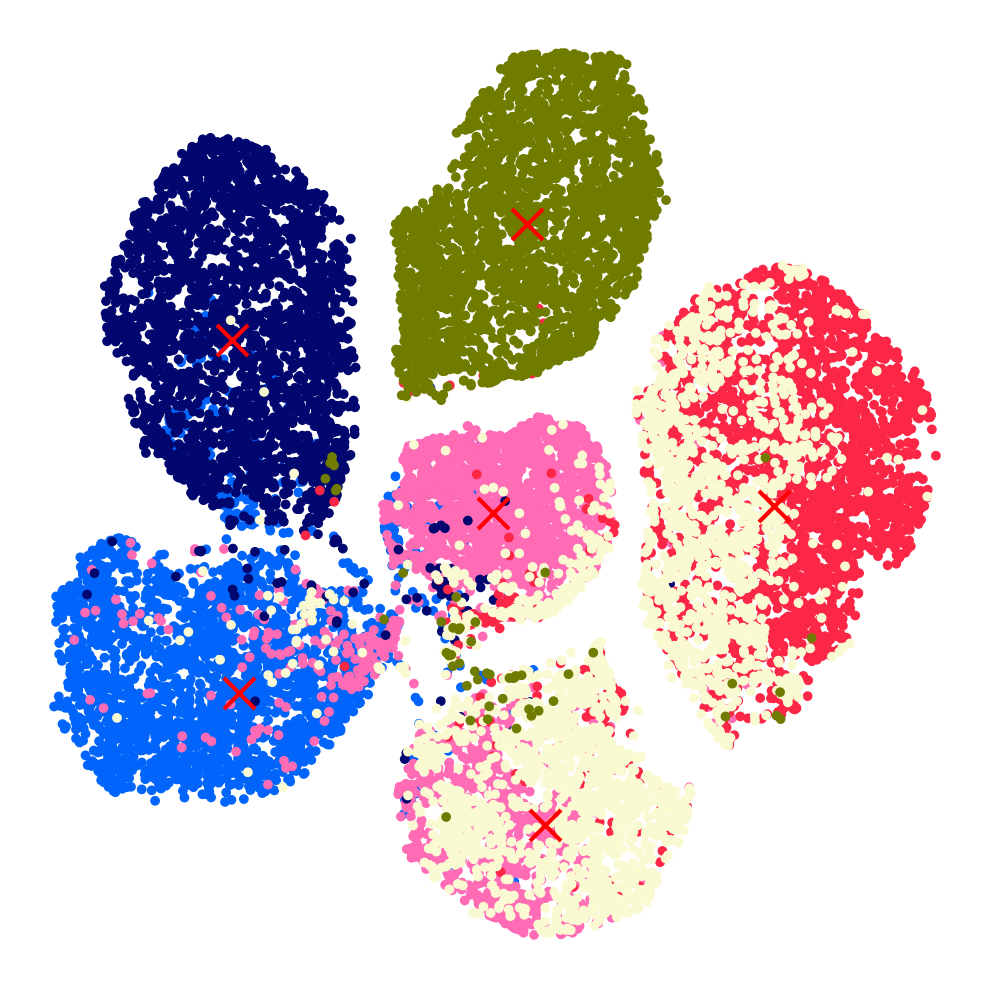

In [12]:
cluster_centers = autoencoder.get_cluster_centers().cpu().detach().numpy()
data, latent_data, labels = autoencoder.get_latent_data()
visualization.plot_tsne(latent_data, labels, clustering, cluster_centers, autoencoder.data_dir_path)